<a href="https://colab.research.google.com/github/luanbispo13/estrutura_dados_2/blob/main/grafos_bfs_dfs/solucao_grafos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Atividade - Grafos, BFS e DFS

## Identificação
- Nome: Luan Bispo Silva
- RGM: 32635648
- Turma: Estrutura de Dados II
- Docente: Profa. Kadidja Valéria
- Data: 30/10
- Ferramenta utilizada: Google Colab com Python (matplotlib e networkx)

## Contexto
Nessa atividade eu montei uma rede de cidades inventada e usei BFS e DFS para achar caminhos de Brasília até Curitiba. A notícia da pane de GPS no Aeroporto de Brasília (G1, 22/09/2026) foi só a ideia para o problema. As cidades, as conexões e os bloqueios são inventados, então não dá para usar isso para planejar voo de verdade.

Referência: GOMES, Paulo César Rodacki. *Grafos: conceitos fundamentais, algoritmos e aplicações*. Blumenau: Editora IFC, 2022.

### Observações sobre os dados usados
O material não diz como montar o grafo, então eu escolhi as cidades, as conexões e os bloqueios. Os bloqueios são só suposições para a simulação, não são resultado da pane.

P: Quantas conexões eu preciso bloquear para Brasília não conseguir mais chegar em Curitiba? E como BFS e DFS se comportam em cada cenário?

## 1. Bibliotecas

O BFS e o DFS eu fiz só com a biblioteca padrão do Python. O `matplotlib` serve para desenhar e o `networkx` eu usei só nos testes, para conferir se meus resultados batem com os de uma biblioteca pronta. No Colab já vem tudo instalado.

In [1]:
import sys
import unicodedata
import difflib
import unittest
from collections import deque
from copy import deepcopy
from itertools import combinations

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx  # só para conferir nos testes

print("Python     :", sys.version.split()[0])
print("networkx   :", nx.__version__)
print("matplotlib :", matplotlib.__version__)

Python     : 3.13.18
networkx   : 3.7
matplotlib : 3.11.2


## 2. O grafo que eu montei

P: desenhe um grafo com pelo menos 7 vértices e conexões justificadas.

R: montei um grafo com 10 cidades (vértices) e 14 conexões (arestas). Ele não é dirigido e não tem pesos, então cada conexão conta como 1 passo. Pensei em dois pontos centrais (São Paulo e Goiânia), algumas rotas diferentes entre Brasília e Curitiba e uma ponta no sul (Florianópolis e Porto Alegre).

Vértices: Brasília, Goiânia, Belo Horizonte, Cuiabá, São Paulo, Campo Grande, Rio de Janeiro, Curitiba, Florianópolis e Porto Alegre.

Conexões e o motivo de cada uma:

| # | Conexão | Justificativa |
|---|---|---|
| 1 | Brasília - Goiânia | ficam perto, no Centro-Oeste |
| 2 | Brasília - Belo Horizonte | liga o Centro-Oeste a Minas |
| 3 | Brasília - Cuiabá | liga o DF ao Mato Grosso |
| 4 | Goiânia - São Paulo | caminho do Centro-Oeste para São Paulo |
| 5 | Goiânia - Campo Grande | caminho de Goiás para o Mato Grosso do Sul |
| 6 | Belo Horizonte - Rio de Janeiro | Minas e Rio ficam perto |
| 7 | Belo Horizonte - São Paulo | Minas e São Paulo ficam perto |
| 8 | Rio de Janeiro - São Paulo | Rio e São Paulo são muito ligadas |
| 9 | São Paulo - Curitiba | entrada no Sul pelo lado de São Paulo |
| 10 | Rio de Janeiro - Curitiba | rota direta do Rio, alternativa a São Paulo |
| 11 | Cuiabá - Campo Grande | liga o Mato Grosso ao Mato Grosso do Sul |
| 12 | Campo Grande - Curitiba | rota pelo oeste até Curitiba |
| 13 | Curitiba - Florianópolis | Paraná e Santa Catarina |
| 14 | Florianópolis - Porto Alegre | Santa Catarina e Rio Grande do Sul (ponta da rede) |

Depois montei a lista de adjacência a partir da lista de arestas. Assim cada conexão entra na lista dos dois lados. O desenho do grafo vem logo abaixo.

O desenho com uma conexão bloqueada está no Experimento B (seção 5).

In [2]:
ARESTAS = [
    ("Brasília", "Goiânia", "ficam perto, no Centro-Oeste"),
    ("Brasília", "Belo Horizonte", "liga o Centro-Oeste a Minas"),
    ("Brasília", "Cuiabá", "liga o DF ao Mato Grosso"),
    ("Goiânia", "São Paulo", "caminho do Centro-Oeste para São Paulo"),
    ("Goiânia", "Campo Grande", "caminho de Goiás para o Mato Grosso do Sul"),
    ("Belo Horizonte", "Rio de Janeiro", "Minas e Rio ficam perto"),
    ("Belo Horizonte", "São Paulo", "Minas e São Paulo ficam perto"),
    ("Rio de Janeiro", "São Paulo", "Rio e São Paulo são muito ligadas"),
    ("São Paulo", "Curitiba", "entrada no Sul pelo lado de São Paulo"),
    ("Rio de Janeiro", "Curitiba", "rota direta do Rio, alternativa a São Paulo"),
    ("Cuiabá", "Campo Grande", "liga o Mato Grosso ao Mato Grosso do Sul"),
    ("Campo Grande", "Curitiba", "rota pelo oeste até Curitiba"),
    ("Curitiba", "Florianópolis", "Paraná e Santa Catarina"),
    ("Florianópolis", "Porto Alegre", "Santa Catarina e Rio Grande do Sul (ponta da rede)"),
]


def construir_grafo(arestas):
    # monta o dicionário de listas de adjacência (grafo não dirigido)
    rede = {}
    for a, b, *_ in arestas:
        rede.setdefault(a, []).append(b)
        rede.setdefault(b, []).append(a)
    return rede


rede = construir_grafo(ARESTAS)

print(f"|V| = {len(rede)} vértices | |E| = {len(ARESTAS)} arestas\n")
print("Lista de adjacência (grau entre parênteses):")
for vertice, vizinhos in rede.items():
    print(f"  {vertice} ({len(vizinhos)}): {vizinhos}")

print("\nConexões e o motivo de cada uma:")
for a, b, motivo in ARESTAS:
    print(f"  {a} - {b}: {motivo}")

|V| = 10 vértices | |E| = 14 arestas

Lista de adjacência (grau entre parênteses):
  Brasília (3): ['Goiânia', 'Belo Horizonte', 'Cuiabá']
  Goiânia (3): ['Brasília', 'São Paulo', 'Campo Grande']
  Belo Horizonte (3): ['Brasília', 'Rio de Janeiro', 'São Paulo']
  Cuiabá (2): ['Brasília', 'Campo Grande']
  São Paulo (4): ['Goiânia', 'Belo Horizonte', 'Rio de Janeiro', 'Curitiba']
  Campo Grande (3): ['Goiânia', 'Cuiabá', 'Curitiba']
  Rio de Janeiro (3): ['Belo Horizonte', 'São Paulo', 'Curitiba']
  Curitiba (4): ['São Paulo', 'Rio de Janeiro', 'Campo Grande', 'Florianópolis']
  Florianópolis (2): ['Curitiba', 'Porto Alegre']
  Porto Alegre (1): ['Florianópolis']

Conexões e o motivo de cada uma:
  Brasília - Goiânia: ficam perto, no Centro-Oeste
  Brasília - Belo Horizonte: liga o Centro-Oeste a Minas
  Brasília - Cuiabá: liga o DF ao Mato Grosso
  Goiânia - São Paulo: caminho do Centro-Oeste para São Paulo
  Goiânia - Campo Grande: caminho de Goiás para o Mato Grosso do Sul
  Belo Hor

### Desenho do grafo

D: coloquei as cidades mais ou menos onde ficam no mapa (longitude e latitude), só para o desenho ficar fácil de entender. O grafo não usa distância.

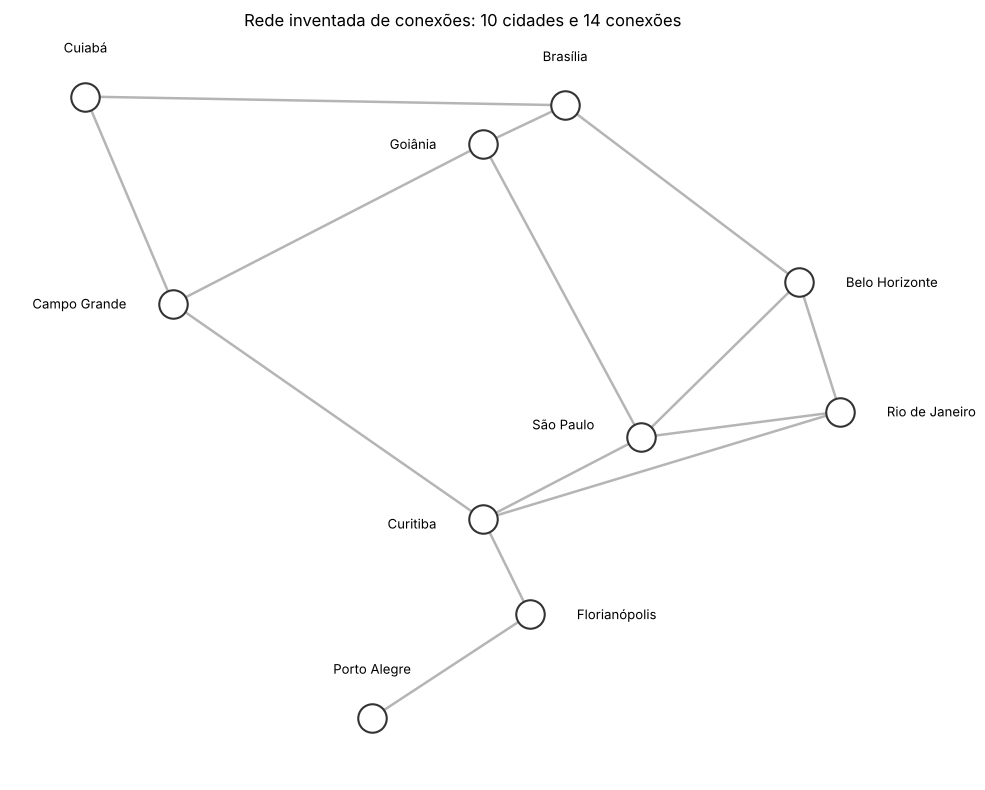

In [3]:
POSICOES = {  # (longitude, latitude) aproximadas, só para desenhar
    "Brasília": (-47.9, -15.8), "Goiânia": (-49.3, -16.7), "Belo Horizonte": (-43.9, -19.9),
    "Rio de Janeiro": (-43.2, -22.9), "São Paulo": (-46.6, -23.5), "Curitiba": (-49.3, -25.4),
    "Florianópolis": (-48.5, -27.6), "Porto Alegre": (-51.2, -30.0),
    "Cuiabá": (-56.1, -15.6), "Campo Grande": (-54.6, -20.4),
}
# onde o nome da cidade fica em relação à bolinha: (dx, dy, alinhamento horizontal, alinhamento vertical)
ROTULO_PADRAO = (0.0, 0.95, "center", "bottom")  # em cima da bolinha
ROTULOS = {
    "Goiânia": (-0.8, 0.0, "right", "center"),
    "Campo Grande": (-0.8, 0.0, "right", "center"),
    "Belo Horizonte": (0.8, 0.0, "left", "center"),
    "Rio de Janeiro": (0.8, 0.0, "left", "center"),
    "São Paulo": (-0.8, 0.3, "right", "center"),
    "Curitiba": (-0.8, -0.1, "right", "center"),
    "Florianópolis": (0.8, 0.0, "left", "center"),
}
COR_CAMINHO, COR_BLOQUEIO, COR_BASE = "#1f77b4", "#d62728", "#b5b5b5"
COR_ORIGEM, COR_DESTINO = "#2ca02c", "#9467bd"


def desenhar(ax, titulo, bloqueios=(), caminho=None, destaques=None):
    bloqueadas = {frozenset(par) for par in bloqueios}
    no_caminho = {frozenset(par) for par in zip(caminho, caminho[1:])} if caminho else set()
    for a, b, _ in ARESTAS:
        (x1, y1), (x2, y2) = POSICOES[a], POSICOES[b]
        chave = frozenset((a, b))
        if chave in bloqueadas:
            estilo = dict(color=COR_BLOQUEIO, linestyle="--", linewidth=2.4, zorder=2)
        elif chave in no_caminho:
            estilo = dict(color=COR_CAMINHO, linewidth=5, zorder=2)
        else:
            estilo = dict(color=COR_BASE, linewidth=1.8, zorder=1)
        ax.plot([x1, x2], [y1, y2], **estilo)
    for vertice, (x, y) in POSICOES.items():
        cor = (destaques or {}).get(vertice, "#ffffff")
        ax.scatter(x, y, s=420, color=cor, edgecolor="#333333", linewidth=1.5, zorder=3)
        dx, dy, ha, va = ROTULOS.get(vertice, ROTULO_PADRAO)
        ax.text(x + dx, y + dy, vertice, ha=ha, va=va, fontsize=9.5, zorder=4,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    ax.set_title(titulo, fontsize=12)
    ax.set_axis_off()
    ax.margins(0.1)


def legenda(fig):
    itens = [Line2D([0], [0], color=COR_BASE, lw=2, label="Conexão disponível"),
             Line2D([0], [0], color=COR_CAMINHO, lw=5, label="Caminho encontrado"),
             Line2D([0], [0], color=COR_BLOQUEIO, lw=2.4, ls="--", label="Conexão bloqueada")]
    for cor, rotulo in ((COR_ORIGEM, "Origem"), (COR_DESTINO, "Destino")):
        itens.append(Line2D([0], [0], marker="o", color="w", markerfacecolor=cor,
                            markeredgecolor="#333333", markersize=11, label=rotulo))
    fig.legend(handles=itens, loc="lower center", ncol=len(itens), frameon=False, fontsize=10)


fig, ax = plt.subplots(figsize=(10, 8))
desenhar(ax, f"Rede inventada de conexões: {len(rede)} cidades e {len(ARESTAS)} conexões")
fig.tight_layout()
fig.savefig("grafo_diagrama.png", dpi=150, bbox_inches="tight")
plt.show()

R: esse é o grafo com as conexões da tabela acima. Cada traço cinza é uma conexão.

## 3. As funções

P: implementar BFS, DFS e o bloqueio de conexões sem mexer no grafo original.

R:
- BFS: usa uma fila (`deque`). Eu marco a cidade como visitada na hora em que coloco ela na fila.
- DFS: usa uma pilha (uma lista). Empilho os vizinhos de trás para frente, assim o primeiro vizinho da lista é o primeiro a ser explorado. Fiz sem recursão para não esbarrar no limite de recursão do Python.
- Os dois devolvem a lista de cidades do caminho. Se origem e destino forem a mesma cidade, devolvem só `[origem]`. Se não existe caminho, devolvem `None`.
- Bloqueio: a função `bloquear_conexoes` trabalha numa cópia da rede, então o grafo original nunca muda.
- Menor corte: a função `menor_corte` testa todas as combinações de bloqueios até achar a menor quantidade que separa origem e destino. Como são só 14 arestas, deu para testar tudo.

In [4]:
def normalizar(texto):
    # minúsculas, sem acento e sem espaço repetido
    decomposto = unicodedata.normalize("NFD", texto)
    sem_acento = "".join(c for c in decomposto if unicodedata.category(c) != "Mn")
    return " ".join(sem_acento.casefold().split())


def resolver_vertice(rede, nome):
    # devolve o nome certo da cidade ou dá erro com sugestão
    indice = {normalizar(v): v for v in rede}
    chave = normalizar(nome)
    if chave in indice:
        return indice[chave]
    sugestoes = [indice[k] for k in difflib.get_close_matches(chave, list(indice), n=3, cutoff=0.5)]
    mensagem = f"Vértice '{nome}' não existe na rede."
    if sugestoes:
        mensagem += f" Você quis dizer: {', '.join(sugestoes)}?"
    raise ValueError(mensagem)


def _exigir_vertices(rede, *vertices):
    for v in vertices:
        if v not in rede:
            raise ValueError(f"Vértice '{v}' não existe na rede.")


def bfs(rede, origem, destino):
    # busca em largura: acha o caminho com menos arestas
    _exigir_vertices(rede, origem, destino)
    fila = deque([(origem, [origem])])
    visitados = {origem}
    while fila:
        atual, caminho = fila.popleft()
        if atual == destino:
            return caminho
        for vizinho in rede[atual]:
            if vizinho not in visitados:
                visitados.add(vizinho)
                fila.append((vizinho, caminho + [vizinho]))
    return None


def dfs(rede, origem, destino):
    # busca em profundidade: acha um caminho, que depende da ordem dos vizinhos
    _exigir_vertices(rede, origem, destino)
    pilha = [(origem, [origem])]
    visitados = set()
    while pilha:
        atual, caminho = pilha.pop()
        if atual in visitados:
            continue
        visitados.add(atual)
        if atual == destino:
            return caminho
        for vizinho in reversed(rede[atual]):
            if vizinho not in visitados:
                pilha.append((vizinho, caminho + [vizinho]))
    return None


def contar_arestas(caminho):
    return None if caminho is None else len(caminho) - 1


def bloquear_conexoes(rede, bloqueios):
    # devolve uma cópia da rede sem as conexões bloqueadas (tira dos dois lados)
    copia = {no: vizinhos.copy() for no, vizinhos in rede.items()}
    for a, b in bloqueios:
        a, b = resolver_vertice(rede, a), resolver_vertice(rede, b)
        if b not in rede[a]:
            raise ValueError(f"A conexão {a}-{b} não existe na rede.")
        if b in copia[a]:
            copia[a].remove(b)
        if a in copia[b]:
            copia[b].remove(a)
    return copia


def arestas_da_rede(rede):
    # conjunto das arestas, cada uma como tupla ordenada
    return sorted({tuple(sorted((a, b))) for a, vizinhos in rede.items() for b in vizinhos})


def menor_corte(rede, origem, destino):
    # testa k = 1, 2, 3... até achar quantos bloqueios separam origem e destino
    # devolve k e a lista de todas as combinações com k bloqueios
    arestas = arestas_da_rede(rede)
    for k in range(1, len(arestas) + 1):
        cortes = [c for c in combinations(arestas, k)
                  if bfs(bloquear_conexoes(rede, c), origem, destino) is None]
        if cortes:
            return k, cortes
    return None, []


def formatar(caminho):
    if caminho is None:
        return "sem caminho (origem e destino ficaram separados)"
    return f"{' → '.join(caminho)}  ({contar_arestas(caminho)} arestas)"


def comparar(rede, origem, destino, bloqueios=(), titulo="Normal"):
    # roda BFS e DFS no cenário pedido e imprime
    origem, destino = resolver_vertice(rede, origem), resolver_vertice(rede, destino)
    cenario = bloquear_conexoes(rede, bloqueios) if bloqueios else rede
    print(f"Cenário: {titulo}  |  {origem} → {destino}")
    for nome, algoritmo in (("BFS", bfs), ("DFS", dfs)):
        print(f"  {nome}: {formatar(algoritmo(cenario, origem, destino))}")


print("Funções carregadas.")

Funções carregadas.


## 4. Origem e destino escolhidos pelo usuário

P: o programa tem que deixar o usuário digitar a origem e o destino e avisar quando o nome não existe.

R: a função `resolver_vertice` aceita letra maiúscula ou minúscula, com ou sem acento e com espaço sobrando. Se o nome não existe, ela dá erro e sugere cidades parecidas. Também dá erro se o usuário tentar bloquear uma conexão que não existe.

A parte com `input` fica ligada pela variável `EXECUTAR_INTERATIVO`. Para digitar origem, destino e bloqueios (no formato `Cidade A - Cidade B`), é só trocar para `True`. Deixei `False` para o notebook rodar até o fim sem parar.

In [5]:
# testando a validação
for entrada in ["brasilia", "  SAO   paulo ", "Curitba", "Atlantis"]:
    try:
        print(f"{entrada!r:18} -> {resolver_vertice(rede, entrada)}")
    except ValueError as erro:
        print(f"{entrada!r:18} -> ERRO: {erro}")

print()
try:
    bloquear_conexoes(rede, [("Brasília", "Curitiba")])
except ValueError as erro:
    print("Bloqueio de conexão que não existe -> ERRO:", erro)

'brasilia'         -> Brasília
'  SAO   paulo '   -> São Paulo
'Curitba'          -> ERRO: Vértice 'Curitba' não existe na rede. Você quis dizer: Curitiba, Cuiabá?
'Atlantis'         -> ERRO: Vértice 'Atlantis' não existe na rede.

Bloqueio de conexão que não existe -> ERRO: A conexão Brasília-Curitiba não existe na rede.


In [6]:
EXECUTAR_INTERATIVO = False  # troque para True para digitar origem, destino e bloqueios


def ler_vertice(rede, rotulo):
    while True:
        try:
            return resolver_vertice(rede, input(f"{rotulo}: "))
        except ValueError as erro:
            print("  ", erro)


def ler_bloqueios(rede):
    bloqueios = []
    while True:
        texto = input("Bloquear conexão ('Cidade A - Cidade B'; Enter para terminar): ").strip()
        if not texto:
            return bloqueios
        partes = [p.strip() for p in texto.replace("–", "-").split("-")]  # aceita - ou –
        if len(partes) != 2:
            print("   Use o formato 'Cidade A - Cidade B'.")
            continue
        try:
            par = tuple(resolver_vertice(rede, p) for p in partes)
            bloquear_conexoes(rede, [par])  # só valida: dá erro se a conexão não existe
            bloqueios.append(par)
        except ValueError as erro:
            print("  ", erro)


def modo_interativo(rede):
    print("Cidades disponíveis:", ", ".join(sorted(rede)))
    origem = ler_vertice(rede, "Origem")
    destino = ler_vertice(rede, "Destino")
    bloqueios = ler_bloqueios(rede)
    comparar(rede, origem, destino, titulo="Normal")
    if bloqueios:
        print()
        comparar(rede, origem, destino, bloqueios, titulo="Com bloqueios")


if EXECUTAR_INTERATIVO:
    modo_interativo(rede)
else:
    print("Modo interativo desligado (EXECUTAR_INTERATIVO = False).")

Modo interativo desligado (EXECUTAR_INTERATIVO = False).


## 5. Experimentos

### Experimento A - rede completa

P: rodar BFS e DFS na rede completa (Brasília → Curitiba) e contar as arestas de cada caminho.

In [7]:
comparar(rede, "Brasília", "Curitiba", titulo="Normal (rede completa)")

Cenário: Normal (rede completa)  |  Brasília → Curitiba
  BFS: Brasília → Goiânia → São Paulo → Curitiba  (3 arestas)
  DFS: Brasília → Goiânia → São Paulo → Belo Horizonte → Rio de Janeiro → Curitiba  (5 arestas)


R: o BFS achou um caminho com 3 arestas (Brasília → Goiânia → São Paulo → Curitiba). O DFS achou um com 5 arestas, passando por Belo Horizonte e Rio de Janeiro antes de chegar em Curitiba. Os dois chegam lá, mas só o BFS sempre acha o menor caminho.

### Experimento B - bloqueio Goiânia-São Paulo

P: bloquear a conexão Goiânia-São Paulo e rodar de novo.

D: esse bloqueio é uma suposição minha para a simulação, não aconteceu de verdade.

D: na figura, o caminho encontrado fica em azul, a conexão bloqueada em vermelho tracejado, a origem em verde e o destino em roxo.

Cenário: Bloqueio Goiânia-São Paulo  |  Brasília → Curitiba
  BFS: Brasília → Goiânia → Campo Grande → Curitiba  (3 arestas)
  DFS: Brasília → Goiânia → Campo Grande → Curitiba  (3 arestas)


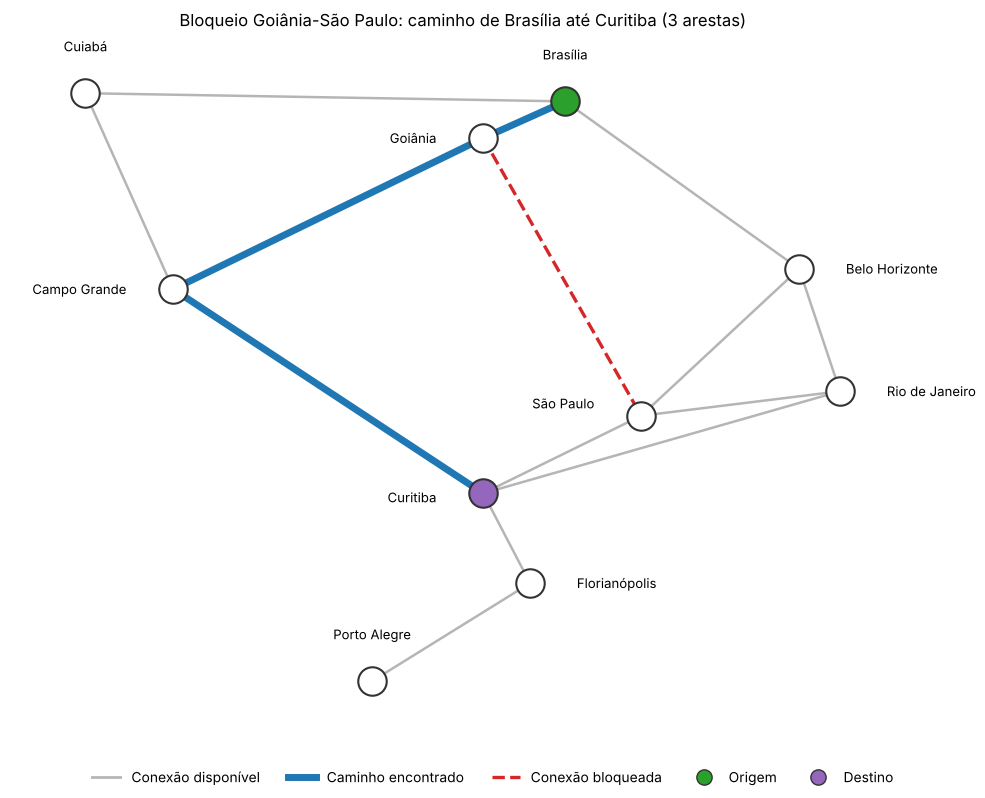

In [8]:
bloqueio_b = [("Goiânia", "São Paulo")]
comparar(rede, "Brasília", "Curitiba", bloqueio_b, titulo="Bloqueio Goiânia-São Paulo")

# nesse cenário o BFS e o DFS acham o mesmo caminho, então desenho um só
cenario_b = bloquear_conexoes(rede, bloqueio_b)
caminho_b = bfs(cenario_b, "Brasília", "Curitiba")
assert caminho_b == dfs(cenario_b, "Brasília", "Curitiba")

fig, ax = plt.subplots(figsize=(10, 8))
desenhar(ax, f"Bloqueio Goiânia-São Paulo: caminho de Brasília até Curitiba ({contar_arestas(caminho_b)} arestas)",
         bloqueio_b, caminho_b, {"Brasília": COR_ORIGEM, "Curitiba": COR_DESTINO})
legenda(fig)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig("grafo_bloqueio.png", dpi=150, bbox_inches="tight")
plt.show()

R: sem a conexão Goiânia-São Paulo, os dois acharam o mesmo caminho: Brasília → Goiânia → Campo Grande → Curitiba (3 arestas). Aqui o DFS se saiu bem porque o primeiro vizinho que ele tenta (Goiânia) já leva até Curitiba passando por Campo Grande.

### Experimento C - segunda conexão bloqueada

P: bloquear mais uma conexão e ver se ainda existe caminho, explicando com conectividade.

D: bloqueei Goiânia-São Paulo e Belo Horizonte-Rio de Janeiro. Depois calculei o menor número de bloqueios que separa Brasília de Curitiba.

In [9]:
bloqueios_c = [("Goiânia", "São Paulo"), ("Belo Horizonte", "Rio de Janeiro")]
comparar(rede, "Brasília", "Curitiba", bloqueios_c, titulo="Bloqueio duplo")

print()
k, cortes = menor_corte(rede, "Brasília", "Curitiba")
print(f"Menor número de conexões que isola Brasília de Curitiba: {k}")
print(f"Combinações de {k} bloqueios que separam as duas: {len(cortes)}")
for corte in cortes:
    print("  -", " | ".join(f"{a}-{b}" for a, b in corte))

print("\nCaminhos entre Brasília e Curitiba sem nenhuma aresta em comum (networkx):")
G_REF = nx.Graph([(a, b) for a, b, _ in ARESTAS])
for caminho in nx.edge_disjoint_paths(G_REF, "Brasília", "Curitiba"):
    print("  -", " → ".join(caminho))

print()
comparar(rede, "Brasília", "Curitiba", cortes[0], titulo=f"Um corte mínimo ({k} bloqueios)")

Cenário: Bloqueio duplo  |  Brasília → Curitiba
  BFS: Brasília → Goiânia → Campo Grande → Curitiba  (3 arestas)
  DFS: Brasília → Goiânia → Campo Grande → Curitiba  (3 arestas)

Menor número de conexões que isola Brasília de Curitiba: 3
Combinações de 3 bloqueios que separam as duas: 4
  - Belo Horizonte-Brasília | Brasília-Cuiabá | Brasília-Goiânia
  - Belo Horizonte-Brasília | Brasília-Goiânia | Campo Grande-Cuiabá
  - Belo Horizonte-Brasília | Campo Grande-Curitiba | Goiânia-São Paulo
  - Campo Grande-Curitiba | Curitiba-Rio de Janeiro | Curitiba-São Paulo

Caminhos entre Brasília e Curitiba sem nenhuma aresta em comum (networkx):
  - Brasília → Goiânia → São Paulo → Curitiba
  - Brasília → Belo Horizonte → Rio de Janeiro → Curitiba
  - Brasília → Cuiabá → Campo Grande → Curitiba

Cenário: Um corte mínimo (3 bloqueios)  |  Brasília → Curitiba
  BFS: sem caminho (origem e destino ficaram separados)
  DFS: sem caminho (origem e destino ficaram separados)


R: com os dois bloqueios ainda existe caminho (Brasília → Goiânia → Campo Grande → Curitiba), e o BFS e o DFS acharam o mesmo.

Existem 3 caminhos entre Brasília e Curitiba que não têm nenhuma aresta em comum (um pela Goiânia-São Paulo, outro pela Belo Horizonte-Rio e outro pela Cuiabá-Campo Grande). Cada bloqueio corta no máximo um deles, então com 1 ou 2 bloqueios sempre sobra um caminho. Para separar as duas cidades precisa de 3 bloqueios, e existem 4 combinações que fazem isso (uma delas são as 3 conexões de Brasília). Isso bate com o teorema de Menger, e conferi o número 3 nos testes com `nx.edge_connectivity`.

### Experimento D - ordem dos vizinhos

P: mudar a ordem de uma lista de vizinhos e explicar por que o DFS pode mudar sem o grafo mudar.

D: inverti a lista de vizinhos de Brasília. As arestas são exatamente as mesmas, só muda a ordem.

In [10]:
rede_reordenada = deepcopy(rede)
rede_reordenada["Brasília"].reverse()

print("Mesmas arestas nos dois grafos:", arestas_da_rede(rede) == arestas_da_rede(rede_reordenada))
print("Vizinhos de Brasília - original  :", rede["Brasília"])
print("Vizinhos de Brasília - invertidos:", rede_reordenada["Brasília"])
print()
comparar(rede, "Brasília", "Curitiba", titulo="Ordem original")
print()
comparar(rede_reordenada, "Brasília", "Curitiba", titulo="Vizinhos de Brasília invertidos")

Mesmas arestas nos dois grafos: True
Vizinhos de Brasília - original  : ['Goiânia', 'Belo Horizonte', 'Cuiabá']
Vizinhos de Brasília - invertidos: ['Cuiabá', 'Belo Horizonte', 'Goiânia']

Cenário: Ordem original  |  Brasília → Curitiba
  BFS: Brasília → Goiânia → São Paulo → Curitiba  (3 arestas)
  DFS: Brasília → Goiânia → São Paulo → Belo Horizonte → Rio de Janeiro → Curitiba  (5 arestas)

Cenário: Vizinhos de Brasília invertidos  |  Brasília → Curitiba
  BFS: Brasília → Cuiabá → Campo Grande → Curitiba  (3 arestas)
  DFS: Brasília → Cuiabá → Campo Grande → Goiânia → São Paulo → Belo Horizonte → Rio de Janeiro → Curitiba  (7 arestas)


R: o DFS foi de 5 para 7 arestas só por causa da ordem da lista. Ele sempre vai fundo no primeiro vizinho que aparece (agora Cuiabá → Campo Grande → Goiânia → São Paulo → ...) antes de testar os outros. O BFS continuou com 3 arestas, porque ele olha todos os vizinhos de um nível antes de descer para o próximo.

### Experimento E - todos os pares de cidades (extra)

P: comparar o tamanho dos caminhos de BFS e DFS para todos os pares de cidades.

In [11]:
vertices = sorted(rede)
pares = [(o, d) for o in vertices for d in vertices if o != d]
comp_bfs = [contar_arestas(bfs(rede, o, d)) for o, d in pares]
comp_dfs = [contar_arestas(dfs(rede, o, d)) for o, d in pares]
mais_longos = sum(1 for b, d in zip(comp_bfs, comp_dfs) if d > b)

print(f"Pares ordenados analisados: {len(pares)}")
print(f"Média de arestas - BFS: {sum(comp_bfs) / len(pares):.2f} | DFS: {sum(comp_dfs) / len(pares):.2f}")
print(f"Pares em que o DFS devolveu caminho mais longo que o BFS: {mais_longos} ({mais_longos / len(pares):.0%})")
print(f"Maior diferença (DFS menos BFS): {max(d - b for b, d in zip(comp_bfs, comp_dfs))} arestas")

Pares ordenados analisados: 90
Média de arestas - BFS: 2.16 | DFS: 4.31
Pares em que o DFS devolveu caminho mais longo que o BFS: 59 (66%)
Maior diferença (DFS menos BFS): 6 arestas


R: em média o BFS usou 2,16 arestas e o DFS 4,31. Em 59 dos 90 pares (66%) o DFS achou um caminho mais longo que o BFS, e a maior diferença foi de 6 arestas.

## 6. Testes

P: testar se as funções estão certas, incluindo os casos de erro e de "sem caminho".

R: usei o `unittest` e comparei meus resultados com os do `networkx` (menor caminho, existência de caminho e conectividade por arestas). A última linha da célula dá erro se algum teste falhar, então se a saída abaixo terminou em `OK`, todos passaram.

In [12]:
def grafo_ref(bloqueios=()):
    g = G_REF.copy()
    g.remove_edges_from(bloqueios)
    return g


def caminho_valido(rede, caminho, origem, destino):
    return (caminho[0] == origem and caminho[-1] == destino
            and len(set(caminho)) == len(caminho)
            and all(b in rede[a] for a, b in zip(caminho, caminho[1:])))


class TestesGrafo(unittest.TestCase):
    def test_grafo_tem_ao_menos_7_vertices_e_e_simetrico(self):
        self.assertGreaterEqual(len(rede), 7)
        for a, vizinhos in rede.items():
            self.assertEqual(len(vizinhos), len(set(vizinhos)))  # sem aresta repetida
            self.assertNotIn(a, vizinhos)                        # sem laço
            for b in vizinhos:
                self.assertIn(a, rede[b])                        # simetria

    def test_bfs_minimo_e_dfs_valido_em_todos_os_pares(self):
        for o in rede:
            for d in rede:
                cb, cd = bfs(rede, o, d), dfs(rede, o, d)
                self.assertTrue(caminho_valido(rede, cb, o, d))
                self.assertTrue(caminho_valido(rede, cd, o, d))
                self.assertEqual(contar_arestas(cb), nx.shortest_path_length(G_REF, o, d))
                self.assertGreaterEqual(contar_arestas(cd), contar_arestas(cb))

    def test_origem_igual_destino(self):
        self.assertEqual(bfs(rede, "Curitiba", "Curitiba"), ["Curitiba"])
        self.assertEqual(dfs(rede, "Curitiba", "Curitiba"), ["Curitiba"])

    def test_vertice_inexistente_gera_erro_com_sugestao(self):
        with self.assertRaises(ValueError) as ctx:
            resolver_vertice(rede, "Curitba")
        self.assertIn("Curitiba", str(ctx.exception))
        with self.assertRaises(ValueError):
            resolver_vertice(rede, "Atlantis")
        with self.assertRaises(ValueError):
            bfs(rede, "Atlantis", "Curitiba")
        with self.assertRaises(ValueError):
            dfs(rede, "Brasília", "Atlantis")

    def test_normalizacao_aceita_caixa_acento_e_espacos(self):
        self.assertEqual(resolver_vertice(rede, "  são   PAULO "), "São Paulo")
        self.assertEqual(resolver_vertice(rede, "brasilia"), "Brasília")
        self.assertEqual(resolver_vertice(rede, "florianopolis"), "Florianópolis")

    def test_bloqueio_nao_altera_original_e_remove_nos_dois_sentidos(self):
        antes = deepcopy(rede)
        novo = bloquear_conexoes(rede, [("Goiânia", "São Paulo")])
        self.assertEqual(rede, antes)
        self.assertIn("São Paulo", rede["Goiânia"])
        self.assertNotIn("São Paulo", novo["Goiânia"])
        self.assertNotIn("Goiânia", novo["São Paulo"])

    def test_bloqueio_de_conexao_inexistente_gera_erro(self):
        with self.assertRaises(ValueError):
            bloquear_conexoes(rede, [("Brasília", "Curitiba")])

    def test_caso_sem_caminho_retorna_none(self):
        isolado = bloquear_conexoes(rede, [("Brasília", v) for v in rede["Brasília"]])
        self.assertIsNone(bfs(isolado, "Brasília", "Curitiba"))
        self.assertIsNone(dfs(isolado, "Brasília", "Curitiba"))
        self.assertIsNone(contar_arestas(None))

    def test_conectividade_igual_ao_networkx_com_1_e_2_bloqueios(self):
        for k in (1, 2):
            for bloqueios in combinations(arestas_da_rede(rede), k):
                cenario = bloquear_conexoes(rede, bloqueios)
                ref = grafo_ref(bloqueios)
                for o in rede:
                    for d in rede:
                        existe = nx.has_path(ref, o, d)
                        self.assertEqual(bfs(cenario, o, d) is not None, existe)
                        self.assertEqual(dfs(cenario, o, d) is not None, existe)

    def test_menor_corte_igual_a_conectividade_por_arestas_do_networkx(self):
        k, cortes = menor_corte(rede, "Brasília", "Curitiba")
        self.assertEqual(k, nx.edge_connectivity(G_REF, "Brasília", "Curitiba"))
        for corte in cortes:
            self.assertIsNone(bfs(bloquear_conexoes(rede, corte), "Brasília", "Curitiba"))

    def test_dfs_depende_da_ordem_dos_vizinhos(self):
        outra = deepcopy(rede)
        outra["Brasília"].reverse()
        self.assertEqual(arestas_da_rede(rede), arestas_da_rede(outra))
        self.assertNotEqual(dfs(rede, "Brasília", "Curitiba"), dfs(outra, "Brasília", "Curitiba"))


suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestesGrafo)
resultado_testes = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(suite)
assert resultado_testes.wasSuccessful(), "Há testes falhando"

test_bfs_minimo_e_dfs_valido_em_todos_os_pares (__main__.TestesGrafo.test_bfs_minimo_e_dfs_valido_em_todos_os_pares) ... 

ok


test_bloqueio_de_conexao_inexistente_gera_erro (__main__.TestesGrafo.test_bloqueio_de_conexao_inexistente_gera_erro) ... 

ok


test_bloqueio_nao_altera_original_e_remove_nos_dois_sentidos (__main__.TestesGrafo.test_bloqueio_nao_altera_original_e_remove_nos_dois_sentidos) ... 

...

test_origem_igual_destino (__main__.TestesGrafo.test_origem_igual_destino) ... 

ok


test_vertice_inexistente_gera_erro_com_sugestao (__main__.TestesGrafo.test_vertice_inexistente_gera_erro_com_sugestao) ... 

ok


----------------------------------------------------------------------
Ran 11 tests in 0.199s

OK


R: rodei 11 testes e todos passaram (`OK`). Eles testam: se o grafo tem pelo menos 7 vértices e é simétrico; se o BFS acha o menor caminho e o DFS acha um caminho válido em todos os pares; origem igual ao destino; nome que não existe e nome com acento ou maiúscula; se o bloqueio deixa a rede original intacta; conexão que não existe; caso sem caminho; se a conectividade bate com a do `networkx` para todos os bloqueios de 1 e 2 conexões; o menor corte; e se o DFS muda com a ordem dos vizinhos.

## 7. BFS x DFS e limitações

P: comparar BFS e DFS e explicar as limitações da minha solução.

R:

| Aspecto | BFS | DFS |
|---|---|---|
| Estrutura | fila (FIFO) | pilha (LIFO) |
| Como explora | por níveis, do mais perto para o mais longe | vai fundo em um ramo antes de voltar |
| Menor número de arestas (sem pesos) | sempre acha | nem sempre acha |
| Custo da busca | O(V + E) | O(V + E) |
| Ordem dos vizinhos | só decide entre caminhos do mesmo tamanho | pode mudar o tamanho do caminho (Experimento D) |

Nos testes, os dois sempre concordaram sobre existir ou não um caminho. A diferença está no tamanho do caminho que cada um devolve (3 contra 5 arestas no Experimento A).

Limitações:
- A rede é inventada, não dirigida e sem pesos. "Menor" aqui quer dizer menos arestas, e não menos tempo, distância ou combustível.
- Não considerei regras de aviação, capacidade, horário, clima nem espaço aéreo. O resultado não serve para orientar voo real.
- Guardo o caminho inteiro em cada item da fila e da pilha (`caminho + [vizinho]`). Aqui funciona, mas copia a lista várias vezes. Em um grafo grande seria melhor guardar só o "pai" de cada vértice.
- O menor corte testando todas as combinações só funciona com poucas arestas. Em uma rede grande o certo seria usar fluxo máximo.
- Os bloqueios são suposições minhas, não vieram de dados da pane.

## 8. Questões para reflexão

P: Por que um grafo representa melhor a rede de conexões do que uma árvore binária?

R: na árvore binária cada nó tem no máximo dois filhos e só existe um caminho entre dois nós, então tirar qualquer aresta separa a estrutura. Numa rede de conexões tem cidade com mais de duas ligações (São Paulo tem 4), ciclos e rotas alternativas, e é isso que permite escolher outro caminho quando uma conexão cai.

P: Em qual condição o BFS encontra o menor caminho? O que significa "menor"?

R: quando o grafo não tem pesos (ou todas as arestas valem o mesmo), porque o BFS explora por níveis. "Menor" é o menor número de arestas, e não o menor tempo, distância ou combustível.

P: Por que o DFS pode retornar um caminho diferente do BFS?

R: o DFS vai até o fim de um ramo antes de voltar, e o primeiro caminho que ele encontra depende da ordem dos vizinhos. No Experimento A foram 5 arestas contra 3 do BFS, e no D, com a lista de Brasília invertida, o DFS foi para 7.

P: O que acontece se eu não usar o conjunto de visitados?

R: em um grafo com ciclos (e em grafo não dirigido, onde dá para voltar por qualquer aresta) a busca fica passando pelas mesmas cidades de novo. Se dá para chegar no destino, ela pode até terminar, mas fazendo trabalho repetido. Se não existe caminho, nunca termina.

P: Quais informações a mais seriam necessárias para avaliar tempo ou custo de uma rota?

R: pesos nas arestas (tempo de voo, distância, custo, consumo), direção das conexões (grafo dirigido), horários, capacidade dos aeroportos e restrições de operação. Com pesos, o BFS daria lugar a algoritmos como o de Dijkstra.

P: Por que o resultado do algoritmo não pode ser usado para orientar um voo real?

R: porque o modelo é só um exercício: a rede é inventada e não considera regras de navegação, distância entre aeronaves, clima, autorizações nem capacidade. Operação aérea precisa de sistemas certificados e dados reais.